In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import torch.nn.utils.prune as prune
import copy
from torchvision.models import resnet18
from torchvision.models.quantization import resnet18 as q_resnet18
import pandas as pd
from tqdm import tqdm #I like when it looks pretty
import time
import os
import gzip



device ='cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

STAGE 1 PLAN (just so I have it here):
- load CIFAR-10 and train a ResNet-18 on it, record size and accuracy
- train a smaller student model via knowledge distillation based on resnet
- remove 30, 50, 70% of smallest weights via magnitude pruning from baseline
- apply 8-bit quantization using pytorch to baseline
- Measure trade-offs: model size (MB), accuracy drop (%), inference time
- Deliverables: Compressed models (pruned, quantized, and distilled), comparison table, and a 3-4 page report with visualizations


P.S. I took/sampled some code for ResNet and data loading from https://github.com/deepmancer/resnet-cifar-classification/tree/master (will be referred to as the "github example"). No need to reinvent the wheel for something like this.

In [3]:

### DATA LOADING ###
batch_size=128
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

trainSet = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_train)
train_subset, val_subset = torch.utils.data.random_split(trainSet, [42500, 7500], generator=torch.Generator().manual_seed(1))
testSet = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_test)

trainLoader = torch.utils.data.DataLoader(trainSet, batch_size=batch_size, shuffle=True, num_workers=2)
validLoader = torch.utils.data.DataLoader(val_subset, batch_size=batch_size, shuffle=True, num_workers=2)
testLoader = torch.utils.data.DataLoader(testSet, batch_size=batch_size, shuffle=False, num_workers=2)
    



In [4]:
#HELPERS

###this is just to keep the helpers in one place, I'll define them as I go

def print_size_of_model(model, returning=False):
    
    torch.save(model.state_dict(), "temp.p")
    
    #solution to a past issue achieved with a generative model here, unfortunately
    #I'm compressing the temporarily saved model to accurately reflect the effect of pruning
    with open("temp.p", "rb") as f_in:
        with gzip.open("temp.p.gz", "wb") as f_out:
            f_out.writelines(f_in)
    size = os.path.getsize("temp.p.gz") / 1e6
    print('Size (MB):', size)
    os.remove("temp.p")
    os.remove("temp.p.gz")  
    if returning: return size


In [5]:
#BASELINE CLASSIFIER DEFINITION/TRAINING
baseline_model = resnet18(num_classes=10)
baseline_model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False) # inspired by the github example: this is to avoid downsampling the already small images from CIFAR10 too quickly
baseline_model.maxpool = nn.Identity() 


In [6]:

def train_baseline(model, train_loader, val_loader, epochs=20):
    
    model.to(device)
    
    best_acc = 0.0
    best_model_wts = copy.deepcopy(model.state_dict())

    #I used to have these outside the function, hence the "bl" at the end to differentiate, but I realized that it may have been stupid
    optimizer_bl = optim.SGD(model.parameters(), lr=0.01, momentum=0.9, weight_decay=0.000125)
    criterion_bl = nn.CrossEntropyLoss()
    lr_scheduler_bl = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_bl, T_max=200)


    #train phase
    for epoch in range(epochs):
        print(f'epoch = {epoch}')
        model.train()
        running_loss = 0.0
        
        for inputs, labels in tqdm(train_loader, desc=f"Training, epoch: [{epoch+1}/{epochs}]"):
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer_bl.zero_grad() #clear grads
            outputs = model(inputs) #forward pass
            loss = criterion_bl(outputs, labels) 
            loss.backward() #grads
            optimizer_bl.step() #update

            running_loss += loss.item()
            
        lr_scheduler_bl.step()

        #validation
        model.eval() 
        correct = 0
        total = 0
        
        with torch.no_grad():
            for inputs, labels in tqdm(val_loader, desc=f"Val, epoch: [{epoch+1}/{epochs}]"):
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        val_acc = 100 * correct / total
        avg_loss = running_loss / len(train_loader)
        
        print(f"Epoch [{epoch+1}/{epochs}] Loss: {avg_loss:.4f} | Val Acc: {val_acc:.2f}%")

        #saving best model:
        if val_acc > best_acc:
            best_acc = val_acc
            best_model_wts = copy.deepcopy(model.state_dict())
            torch.save(model.state_dict(), 'resnet18_best.pth')

    print(f"Done. Best val accuracy: {best_acc:.2f}%")
    
    #this is to load best weights into model before returning:
    model.load_state_dict(best_model_wts)
    return model

In [ ]:
trained_model = train_baseline(baseline_model, trainLoader, validLoader, epochs=20) 


epoch = 0


Val, epoch: [1/20]: 100%|██████████████████████████████████████████████████████████████| 59/59 [00:03<00:00, 16.43it/s]


Epoch [1/20] Loss: 1.5717 | Val Acc: 50.95%
epoch = 1


Val, epoch: [2/20]: 100%|██████████████████████████████████████████████████████████████| 59/59 [00:03<00:00, 16.74it/s]


Epoch [2/20] Loss: 1.1332 | Val Acc: 59.57%
epoch = 2


Val, epoch: [3/20]: 100%|██████████████████████████████████████████████████████████████| 59/59 [00:03<00:00, 16.78it/s]


Epoch [3/20] Loss: 0.8820 | Val Acc: 68.52%
epoch = 3


Val, epoch: [4/20]: 100%|██████████████████████████████████████████████████████████████| 59/59 [00:03<00:00, 16.10it/s]


Epoch [4/20] Loss: 0.7342 | Val Acc: 73.32%
epoch = 4


Training, epoch: [5/20]:  44%|████████████████████████▎                              | 173/391 [00:06<00:04, 51.99it/s]

In [6]:
#This is so I don't have to retrain baseline a billion times in the future

trained_baseline = baseline_model
trained_baseline.load_state_dict(torch.load('resnet18_best.pth', weights_only=True))

C:\Users\Cavey\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


<All keys matched successfully>

In [10]:

class StudentNetV2(nn.Module):
    def __init__(self):
        super(StudentNetV2, self).__init__()
        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(16) 
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(32)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)
        self.bn3 = nn.BatchNorm2d(64)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(64 * 4 * 4, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        x = x.view(-1, 64 * 4 * 4)
        x = self.fc1(x)
        return x


In [18]:

class BiggerStudent(nn.Module):
    def __init__(self):
        super(BiggerStudent, self).__init__()
        
        # 3 to 32 
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1, bias=False), # Double conv
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2) 
        )
        
        # 32 to 64
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2) # 16x16 -> 8x8
        )
        
        # 64 to 128
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2) # 8x8 -> 4x4
        )
        
        # Global average pooling: averaging 4x4 spatial dimensions to 1x1
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(128, 10)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        
        x = self.gap(x)       
        x = x.flatten(1)      
        x = self.fc(x)
        return x

In [19]:
student_model = StudentNetV2() 
bigger_student = BiggerStudent()


For knowledge distillation, I referred to the pytorch tutorial: https://docs.pytorch.org/tutorials/beginner/knowledge_distillation_tutorial.html

In [32]:
def train_knowledge_distillation(teacher, student, train_loader, val_loader, epochs=20, T=2.0, soft_target_loss_weight=0.75, ce_loss_weight=0.25, saveAs='student_distilled_best.pth'):
    
    teacher.to(device)
    student.to(device)
    
    teacher.eval()  # teacher is ONLY in eval mode, it is NOT being trained
    student.train() 

    optimizer_sm = optim.SGD(student.parameters(), lr=0.01, momentum=0.9, weight_decay=0.000125)
    lr_scheduler_sm = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_sm, T_max=200)

    kl_div_loss = nn.KLDivLoss(reduction='batchmean') #KL divergence loss
    #p.s. it was manually defined in the tutorial but I found this implementation and decided to use it instead
    
    best_acc = 0.0
    
    for epoch in range(epochs):
        running_loss = 0.0
        load = tqdm(train_loader, desc=f"Distilling Epoch [{epoch+1}/{epochs}]")
        for inputs, labels in load:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer_sm.zero_grad()

            # (gradients not saved, we do not change teacher's weights)
            with torch.no_grad():
                teacher_logits = teacher(inputs)

            student_logits = student(inputs)

            # softening logits with softmax and log
            # temperature T softens the probability distribution to reveal "dark knowledge"
            soft_targets = F.softmax(teacher_logits / T, dim=-1)
            soft_prob = F.log_softmax(student_logits / T, dim=-1)
            
            # Calculate JUST the soft targets loss. Scaled by T**2 as suggested by the authors of the paper "Distilling the knowledge in a neural network"
            soft_targets_loss = kl_div_loss(soft_prob, soft_targets) * (T**2)
            

            # JUST the true label loss
            label_loss = F.cross_entropy(student_logits, labels)

            # actual loss (weighted sum of two losses)
            loss = (soft_target_loss_weight * soft_targets_loss) + (ce_loss_weight * label_loss)
            
            loss.backward()
            optimizer_sm.step()

            running_loss += loss.item()
            load.set_postfix(loss=loss.item())
        
        lr_scheduler_sm.step()

        # validation
        student.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for inputs, labels in tqdm(val_loader, desc=f"Distilling Epoch [{epoch+1}/{epochs}]"):
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = student(inputs)
                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()
        
        val_acc = 100 * correct / total
        print(f"Epoch {epoch+1} | Distillation Loss: {running_loss/len(train_loader):.4f} | Val Acc: {val_acc:.2f}%")
        
        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(student.state_dict(), saveAs)
            
        student.train()

    return student

In [33]:
trained_student = train_knowledge_distillation(trained_baseline, student_model, trainLoader, validLoader, epochs=50, T=4.0)


Distilling Epoch [1/50]: 100%|█████████████████████████████████████████████████████████| 59/59 [00:08<00:00,  7.07it/s]


Epoch 1 | Distillation Loss: 6.4900 | Val Acc: 58.00%


Distilling Epoch [2/50]: 100%|█████████████████████████████████████████████████████████| 59/59 [00:08<00:00,  6.84it/s]


Epoch 2 | Distillation Loss: 4.1441 | Val Acc: 65.48%


Distilling Epoch [3/50]: 100%|█████████████████████████████████████████████████████████| 59/59 [00:09<00:00,  6.54it/s]


...

Epoch 48 | Distillation Loss: 1.6905 | Val Acc: 78.67%


Distilling Epoch [49/50]: 100%|████████████████████████████████████████████████████████| 59/59 [00:11<00:00,  5.35it/s]


Epoch 49 | Distillation Loss: 1.7044 | Val Acc: 79.88%


Distilling Epoch [50/50]: 100%|████████████████████████████████████████████████████████| 59/59 [00:10<00:00,  5.56it/s]

Epoch 50 | Distillation Loss: 1.6831 | Val Acc: 78.67%


In [22]:
trained_student_big = train_knowledge_distillation(teacher=trained_baseline, student=bigger_student, train_loader=trainLoader, val_loader=validLoader, epochs=50, T=4.0, soft_target_loss_weight=0.9, ce_loss_weight=0.1, saveAs="big_student_distilled_best.pth")

Distilling Epoch [1/50]: 100%|█████████████████████████████████████████████████████████| 59/59 [00:09<00:00,  6.31it/s]


Epoch 1 | Distillation Loss: 6.6846 | Val Acc: 53.20%


Distilling Epoch [2/50]: 100%|█████████████████████████████████████████████████████████| 59/59 [00:11<00:00,  4.96it/s]


Epoch 2 | Distillation Loss: 3.2434 | Val Acc: 64.60%


Distilling Epoch [3/50]: 100%|█████████████████████████████████████████████████████████| 59/59 [00:14<00:00,  4.04it/s]


...

Epoch 48 | Distillation Loss: 0.5864 | Val Acc: 90.13%


Distilling Epoch [49/50]: 100%|████████████████████████████████████████████████████████| 59/59 [00:20<00:00,  2.89it/s]


Epoch 49 | Distillation Loss: 0.5738 | Val Acc: 88.55%


Distilling Epoch [50/50]: 100%|████████████████████████████████████████████████████████| 59/59 [00:11<00:00,  5.22it/s]

Epoch 50 | Distillation Loss: 0.5670 | Val Acc: 89.45%


In [9]:
#just for loading 

trained_student = StudentNetV2()
trained_student.load_state_dict(torch.load('student_distilled_best.pth', weights_only=True))
trained_student_big = BiggerStudent()
trained_student_big.load_state_dict(torch.load('big_student_distilled_best.pth', weights_only=True))

<All keys matched successfully>

Tutorial used for pruning: https://docs.pytorch.org/tutorials/intermediate/pruning_tutorial.html

In [14]:
#MAGNITUDE PRUNING

def apply_pruning(model, amount=0.3):
    model_pruned = copy.deepcopy(model)
    
    parameters_to_prune = []
    for name, module in model_pruned.named_modules():
        if isinstance(module, torch.nn.Conv2d) or isinstance(module, torch.nn.Linear):
            parameters_to_prune.append((module, 'weight'))

    prune.global_unstructured(
        parameters_to_prune,
        pruning_method=prune.L1Unstructured,
        amount=amount,
    )
    
    # this makes pruning actually permanent, properly removes pruned weights from disk
    for module, _ in parameters_to_prune:
        prune.remove(module, 'weight')

    return model_pruned

pruned_30 = apply_pruning(baseline_model, amount=0.3)
pruned_50 = apply_pruning(baseline_model, amount=0.5)
pruned_70 = apply_pruning(baseline_model, amount=0.7)

print_size_of_model(baseline_model)
print_size_of_model(pruned_30)
print_size_of_model(pruned_50)
print_size_of_model(pruned_70)

Size (MB): 41.508531
Size (MB): 31.993163
Size (MB): 24.74475
Size (MB): 16.681374


In [34]:
torch.save(pruned_30.state_dict(), "pruned_30.pth")
torch.save(pruned_50.state_dict(), "pruned_50.pth")
torch.save(pruned_70.state_dict(), "pruned_70.pth")

For quantization, I mostly referred to this: https://www.geeksforgeeks.org/deep-learning/pytorch-quantization/


In [15]:
#QUANTIZATION 
def apply_quantization(model, calibration_loader):
    
    #used a generative model to resolve another issue: 
    #I tried making regular resnet quantizable, but the best way to make the code work is to just use the already existing quantizable resnet from torch
    
    q_model = q_resnet18(weights=None, num_classes = 10)
    
    # just replicating the same changes I made to the original resnet
    q_model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
    q_model.maxpool = nn.Identity()
    
    q_model.load_state_dict(model.state_dict(), strict=False)
    
    q_model.eval()
    q_model.to('cpu')
    
    # fusion is needed for quantization accuracy and speed
    q_model.fuse_model()

    #fbgemm is for pc
    q_model.qconfig = torch.quantization.get_default_qconfig('fbgemm')
    torch.quantization.prepare(q_model, inplace=True)

    print("Calibrating!")
    with torch.no_grad():
        for i, (inputs, _) in enumerate(calibration_loader):
            if i > 20: break 
            q_model(inputs)

    print("Quantizing!")
    torch.quantization.convert(q_model, inplace=True)
    print("Done!")
    
    return q_model

# Apply
quantized_model = apply_quantization(baseline_model, trainLoader)


C:\Users\Cavey\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\ao\quantization\observer.py:214: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future release of PyTorch.
  warnings.warn(


Calibrating!
Quantizing!
Done!


In [35]:
torch.save(pruned_70.state_dict(), "8bit_quantized.pth")

In [36]:
# COMPARISON/EVAL/REPORT

def measure_inference_latency(model, loader, device):
    model.to(device)
    model.eval()
    start_time = time.time()
    with torch.no_grad():
        for inputs, _ in loader:
            inputs = inputs.to(device)
            _ = model(inputs)
    end_time = time.time()
    avg_time = (end_time - start_time) / len(loader)
    return avg_time * 1000 #ms

def evaluate_accuracy(model, loader, device):
    model.to(device)
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total

In [37]:
baseline_eval = copy.deepcopy(baseline_model)
baseline_eval.load_state_dict(torch.load('resnet18_best.pth', map_location='cpu'))

models_to_test = {
    "Baseline": baseline_eval,
    "Distilled student": trained_student,
    "Big student": trained_student_big,
    "Pruned 30%": pruned_30,
    "Pruned 50%": pruned_50,
    "Pruned 70%": pruned_70,
    "Quantized (INT8)": quantized_model
}

results = []

print(f"{'Model':<20} | {'Size (MB)':<10} | {'Acc (%)':<10} | {'Latency (ms)':<10}")
print("-" * 60)

for name, model in models_to_test.items():
    #eval_device = 'cpu' if "Quantized" in name else device
    eval_device = 'cpu' #this is for equal evaluation of each model
    
    size = print_size_of_model(model, True)
    acc = evaluate_accuracy(model, testLoader, eval_device)
    lat = measure_inference_latency(model, testLoader, eval_device)
    
    print(f"{name:<20} | {size:<10.2f} | {acc:<10.2f} | {lat:<10.2f}")
    
    results.append({
        "Model": name,
        "Size (MB)": size,
        "Accuracy (%)": acc,
        "Latency (ms)": lat
    })

df = pd.DataFrame(results)
df.to_csv("stage1_results.csv", index=False)
df

Model                | Size (MB)  | Acc (%)    | Latency (ms)
------------------------------------------------------------
Size (MB): 41.508531
Baseline             | 41.51      | 87.63      | 940.31    
Size (MB): 0.130008
Distilled student    | 0.13       | 78.59      | 104.52    
Size (MB): 1.079214
Big student          | 1.08       | 86.37      | 196.97    
Size (MB): 31.99274
Pruned 30%           | 31.99      | 87.59      | 943.63    
Size (MB): 24.744407
Pruned 50%           | 24.74      | 85.51      | 929.90    
Size (MB): 16.681047
Pruned 70%           | 16.68      | 64.10      | 1025.60   
Size (MB): 10.145625
Quantized (INT8)     | 10.15      | 87.50      | 489.59    


,Model,Size (MB),Accuracy (%),Latency (ms)
0,Baseline,41.508531,87.63,940.307219
1,Distilled student,0.130008,78.59,104.518981
2,Big student,1.079214,86.37,196.974664
3,Pruned 30%,31.992740,87.59,943.627433
4,Pruned 50%,24.744407,85.51,929.899146
5,Pruned 70%,16.681047,64.10,1025.596543
6,Quantized (INT8),10.145625,87.50,489.591885


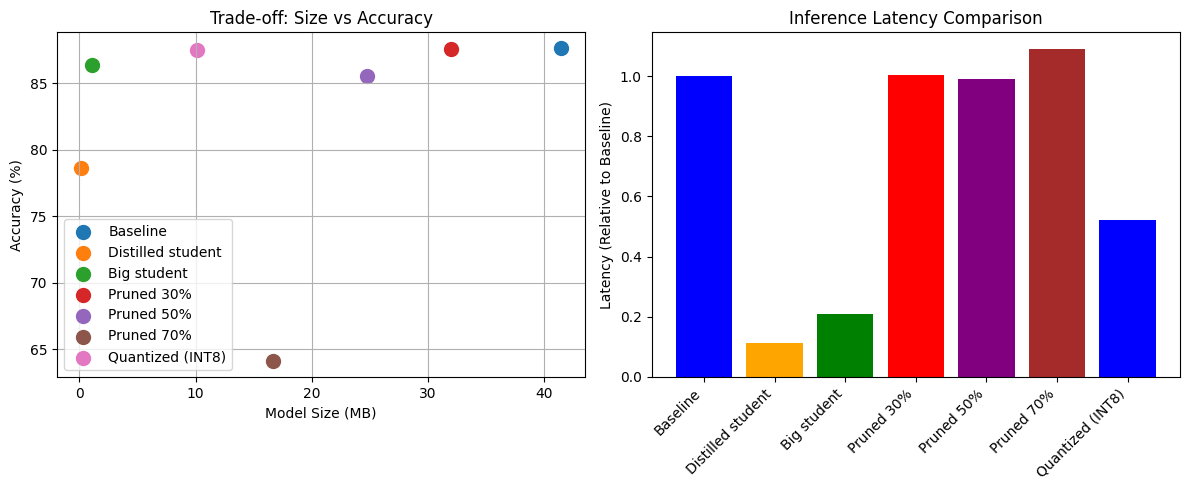

In [39]:
import matplotlib.pyplot as plt

def plot_results(df):
    plt.figure(figsize=(12, 5))

    # size vs accuracy
    plt.subplot(1, 2, 1)
    for i, row in df.iterrows():
        plt.scatter(row['Size (MB)'], row['Accuracy (%)'], label=row['Model'], s=100)
        
    plt.xlabel('Model Size (MB)')
    plt.ylabel('Accuracy (%)')
    plt.title('Trade-off: Size vs Accuracy')
    plt.legend()
    plt.grid(True)

    # latency bar chart (normalized)
    plt.subplot(1, 2, 2)
    baseline_lat = df[df['Model'] == 'Baseline']['Latency (ms)'].values[0]
    df['Rel Latency'] = df['Latency (ms)'] / baseline_lat
    
    colors = ['blue', 'orange', 'green', 'red', 'purple', 'brown']
    plt.bar(df['Model'], df['Rel Latency'], color=colors)
    plt.ylabel('Latency (Relative to Baseline)')
    plt.title('Inference Latency Comparison')
    plt.xticks(rotation=45, ha='right')
    
    plt.tight_layout()
    plt.savefig("compression_analysis.png")
    plt.show()

plot_results(df)